# Laboratorio 10 - Task 3: LIME y explicaciones contrafactuales

**Semilla:** 42  
**Modelo explicado:** el mismo `GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42)` del Task 2.1.

En este notebook implementamos LIME para datos tabulares desde cero (sin la librería `lime`), medimos su estabilidad, lo comparamos con SHAP y construimos explicaciones contrafactuales para el cliente rechazado.

## Preparación: recreamos el modelo del Task 2

Usamos exactamente la misma carga, codificación, división y semilla que en el Task 2.1, así que el modelo es idéntico. Lo comprobamos comparando la exactitud y el AUC con los que guardamos en `results/task2/summary.json`. También cargamos los valores SHAP del Task 2.2 recalculándolos con el mismo fondo de 100 instancias, porque los vamos a necesitar en el Task 3.3.

In [1]:
import json
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.io import arff
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

SEED = 42
np.random.seed(SEED)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'credit-g.arff'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'task3'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Misma carga que en el Task 2 (equivalente local de fetch_openml('credit-g', version=1)).
raw, _ = arff.loadarff(DATA_PATH)
X = pd.DataFrame(raw)
for column in X.select_dtypes(include='object'):
    X[column] = X[column].str.decode('utf-8')
y = X.pop('class').map({'good': 1, 'bad': 0}).astype(int)

categorical_columns = X.select_dtypes(include='object').columns.tolist()
numeric_columns = X.select_dtypes(exclude='object').columns.tolist()
FEATURES = X.columns.tolist()

train_index, test_index = train_test_split(X.index, test_size=0.20, stratify=y, random_state=SEED)
X_train_raw, X_test_raw = X.loc[train_index].copy(), X.loc[test_index].copy()
y_train, y_test = y.loc[train_index].copy(), y.loc[test_index].copy()

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train, X_test = X_train_raw.copy(), X_test_raw.copy()
X_train[categorical_columns] = encoder.fit_transform(X_train_raw[categorical_columns])
X_test[categorical_columns] = encoder.transform(X_test_raw[categorical_columns])
X_train, X_test = X_train.astype(float), X_test.astype(float)

model = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED)
model.fit(X_train, y_train)

def predict_good(rows):
    """Probabilidad de good para una matriz NumPy con las 20 columnas en orden."""
    return model.predict_proba(pd.DataFrame(rows, columns=FEATURES))[:, 1]

test_probability = predict_good(X_test.to_numpy())
accuracy = accuracy_score(y_test, (test_probability >= 0.5).astype(int))
auc = roc_auc_score(y_test, test_probability)

# Comprobamos que es el mismo modelo del Task 2.
task2 = json.loads((PROJECT_ROOT / 'results' / 'task2' / 'summary.json').read_text(encoding='utf-8'))
assert abs(accuracy - task2['task_2_1']['accuracy']) < 1e-12
assert abs(auc - task2['task_2_1']['auc']) < 1e-12

# Valores SHAP del Task 2.2: mismo fondo de 100 instancias y misma semilla.
rng_background = np.random.default_rng(SEED)
background_index = rng_background.choice(X_train.index.to_numpy(), size=100, replace=False)
tree_explainer = shap.TreeExplainer(
    model, data=X_train.loc[background_index],
    feature_perturbation='interventional', model_output='raw',
)
shap_values = np.asarray(tree_explainer(X_test).values)

print(f'Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}')
print(f'Exactitud: {accuracy:.4f} | AUC: {auc:.4f}  (coinciden con el Task 2.1)')
print(f'Valores SHAP del conjunto de prueba: {shap_values.shape}')

C:\Users\richi\Documents\2026_S2_Local\Deep-Learning\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrenamiento: (800, 20) | Prueba: (200, 20)
Exactitud: 0.7750 | AUC: 0.7650  (coinciden con el Task 2.1)
Valores SHAP del conjunto de prueba: (200, 20)


## Task 3.1: LIME desde cero

### Los tres clientes

Usamos los mismos criterios del Task 2.2 para no cambiar de clientes entre técnicas: el aprobado es el de mayor probabilidad de good del conjunto de prueba (cumple $p>0.8$) y el rechazado es el de menor probabilidad. El tercero es el cliente con probabilidad más cercana a 0.5 dentro del intervalo $[0.45, 0.55]$.

In [2]:
approved_position = int(np.argmax(test_probability))
print(approved_position)
rejected_position = int(np.argmin(test_probability))
print(rejected_position)
in_band = np.flatnonzero((test_probability >= 0.45) & (test_probability <= 0.55))
borderline_position = int(in_band[np.argmin(np.abs(test_probability[in_band] - 0.5))])

CLIENTS = {
    'aprobado': approved_position,
    'rechazado': rejected_position,
    'frontera': borderline_position,
}

# El rechazado debe ser el mismo cliente del Task 2.2.
assert X_test.index[rejected_position] == 721

clients_df = pd.DataFrame([
    {
        'cliente': name,
        'posicion_prueba': position,
        'indice_original': int(X_test.index[position]),
        'p_good': test_probability[position],
        'clase_real': 'good' if y_test.iloc[position] == 1 else 'bad',
    }
    for name, position in CLIENTS.items()
])
print(f'Clientes de prueba con p entre 0.45 y 0.55: {len(in_band)}')
display(clients_df.style.format({'p_good': '{:.6f}'}))
display(X_test_raw.iloc[list(CLIENTS.values())].set_axis(list(CLIENTS.keys())).T)

50
76
Clientes de prueba con p entre 0.45 y 0.55: 10


,cliente,posicion_prueba,indice_original,p_good,clase_real
0,aprobado,50,175,0.999447,bad
1,rechazado,76,721,0.051742,bad
2,frontera,87,164,0.503997,good


,aprobado,rechazado,frontera
checking_status,no checking,0<=X<200,no checking
duration,30.0,6.0,36.0
credit_history,all paid,all paid,existing paid
purpose,used car,education,new car
credit_amount,7485.0,433.0,909.0
savings_status,no known savings,>=1000,500<=X<1000
employment,unemployed,<1,>=7
installment_commitment,4.0,4.0,4.0
personal_status,female div/dep/mar,female div/dep/mar,male single
other_parties,none,none,none


### Implementación

La función `lime_tabular` sigue los pasos del enunciado:

1. Genera $N$ vectores binarios $z'$ con $P(z'_j=1)=0.5$.
2. Construye $z$: si $z'_j=1$ conserva el valor del cliente; si $z'_j=0$ toma un valor al azar de la columna $j$ de entrenamiento (cada variable se sortea por separado).
3. Evalúa la probabilidad de good del modelo en cada $z$.
4. Pesa cada muestra con $\pi_x(z)=\exp(-D^2/\sigma^2)$, donde $D^2$ es el número de variables ausentes y $\sigma=\sigma_{rel}\sqrt{20}$.
5. Ajusta la regresión ponderada con regularización sobre las 20 variables, con la solución cerrada $w=(Z'^\top\Pi Z'+\lambda I)^{-1}Z'^\top\Pi y$.
6. Conserva las $K$ variables de mayor $|w|$, vuelve a ajustar solo con ellas y calcula $R^2_w$ y $N_{ef}$.

**Intercepto:** agregamos una columna de unos y **no la penalizamos** (su entrada en la matriz $\lambda I$ vale 0). El intercepto representa la probabilidad cuando todas las variables están ausentes y no hay motivo para empujarlo hacia cero. En lugar de invertir la matriz usamos `np.linalg.solve`, que resuelve el mismo sistema de forma más estable.

Para comprobar la implementación comparamos nuestro ajuste con `sklearn.linear_model.Ridge`, que con `sample_weight` minimiza la misma función y tampoco penaliza el intercepto.

In [3]:
from sklearn.linear_model import Ridge

X_train_np = X_train.to_numpy()
D_PRIME = X_train_np.shape[1]  # 20 variables interpretables
print(f'Número de variables interpretables: {D_PRIME}')
def weighted_ridge(Z_binary, target, weights, lam):
    '''Solución cerrada w = (Z'ᵀ Π Z' + λI)⁻¹ Z'ᵀ Π y con intercepto sin penalizar.'''
    design = np.column_stack([np.ones(len(Z_binary)), Z_binary])
    penalty = lam * np.eye(design.shape[1])
    penalty[0, 0] = 0.0  # el intercepto no se penaliza
    weighted_design = design.T * weights  # equivale a Z'ᵀ Π sin construir la matriz diagonal de N × N
    return np.linalg.solve(weighted_design @ design + penalty, weighted_design @ target)

def weighted_r2(target, fitted, weights):
    weighted_mean = np.sum(weights * target) / np.sum(weights)
    residual = np.sum(weights * (target - fitted) ** 2)
    total = np.sum(weights * (target - weighted_mean) ** 2)
    return 1.0 - residual / total

def lime_tabular(x, n_samples=5000, k=5, lam=1.0, sigma_rel=0.75, seed=SEED, predict=None):
    '''Explica la probabilidad de good del cliente x (vector codificado de 20 variables).

    `predict` permite explicar otra salida del modelo (en el Task 3.5b, los log-odds).
    '''
    predict = predict_good if predict is None else predict
    rng = np.random.default_rng(seed)

    # Pasos 1 y 2: vectores binarios z' y entradas z.
    Z_binary = (rng.random((n_samples, D_PRIME)) < 0.5).astype(float)
    donor_rows = rng.integers(0, len(X_train_np), size=(n_samples, D_PRIME))
    random_values = X_train_np[donor_rows, np.arange(D_PRIME)]
    Z = np.where(Z_binary == 1, x, random_values)

    # Paso 3: salida a explicar.
    target = predict(Z)

    # Paso 4: pesos del kernel.
    absent = D_PRIME - Z_binary.sum(axis=1)  # D² = número de variables ausentes
    sigma = sigma_rel * np.sqrt(D_PRIME)
    weights = np.exp(-absent / sigma**2)

    # Paso 5: ajuste sobre las 20 variables.
    full = weighted_ridge(Z_binary, target, weights, lam)
    full_coef = pd.Series(full[1:], index=FEATURES)

    # Paso 6: nos quedamos con las K de mayor |w| y volvemos a ajustar.
    selected = full_coef.abs().sort_values(ascending=False).index[:k].tolist()
    columns = [FEATURES.index(name) for name in selected]
    refit = weighted_ridge(Z_binary[:, columns], target, weights, lam)
    fitted = refit[0] + Z_binary[:, columns] @ refit[1:]

    return {
        'intercept': refit[0],
        'coef': pd.Series(refit[1:], index=selected),
        'full_coef': full_coef,
        'full_intercept': full[0],
        'r2_w': weighted_r2(target, fitted, weights),
        'n_eff': weights.sum() ** 2 / np.sum(weights**2),
        'Z_binary': Z_binary, 'target': target, 'weights': weights,
    }

# Verificación: nuestra solución cerrada contra sklearn.Ridge en una corrida del cliente rechazado.
check = lime_tabular(X_test.iloc[rejected_position].to_numpy())
reference = Ridge(alpha=1.0, fit_intercept=True).fit(
    check['Z_binary'], check['target'], sample_weight=check['weights']
)
max_coef_error = np.max(np.abs(check['full_coef'].to_numpy() - reference.coef_))
intercept_error = abs(check['full_intercept'] - reference.intercept_)
absent_mean = (D_PRIME - check['Z_binary'].sum(axis=1)).mean()
print(f'Error máximo en coeficientes frente a Ridge: {max_coef_error:.3e}')
print(f'Error en el intercepto frente a Ridge:       {intercept_error:.3e}')
print(f"Muestras: {len(check['target'])} | promedio de variables ausentes: {absent_mean:.2f}")
print(f"Pesos del kernel: mín {check['weights'].min():.3f}, máx {check['weights'].max():.3f}, N_ef = {check['n_eff']:.1f}")

Número de variables interpretables: 20
Error máximo en coeficientes frente a Ridge: 2.835e-15
Error en el intercepto frente a Ridge:       8.993e-15
Muestras: 5000 | promedio de variables ausentes: 10.05
Pesos del kernel: mín 0.202, máx 0.837, N_ef = 4808.4


### Explicaciones de los tres clientes

Aplicamos LIME con los valores de la tabla del enunciado: $N=5000$, $K=5$, $\lambda=1.0$ y $\sigma_{rel}=0.75$, todos con la semilla 42. Un coeficiente $w_j$ positivo significa que conservar el valor real del cliente en la variable $j$, en lugar de un valor tomado al azar, sube la probabilidad de good.

cliente,rango,variable,valor_cliente,w_j
aprobado,1,purpose,used car,+0.1033
aprobado,2,residence_since,1.000000,+0.0732
aprobado,3,age,53.000000,+0.0686
aprobado,4,checking_status,no checking,+0.0567
aprobado,5,savings_status,no known savings,+0.0537
rechazado,1,credit_history,all paid,-0.1986
rechazado,2,credit_amount,433.000000,-0.1544
rechazado,3,duration,6.000000,+0.1335
rechazado,4,savings_status,>=1000,+0.1203
rechazado,5,other_payment_plans,bank,-0.1175


cliente,p_good,intercepto,intercepto + suma de w_j,R2_w,N_ef
aprobado,0.9994,0.7107,1.0661,0.2425,4808.4270
rechazado,0.0517,0.4912,0.2745,0.2995,4808.4270
frontera,0.5040,0.6351,0.5860,0.2790,4808.4270


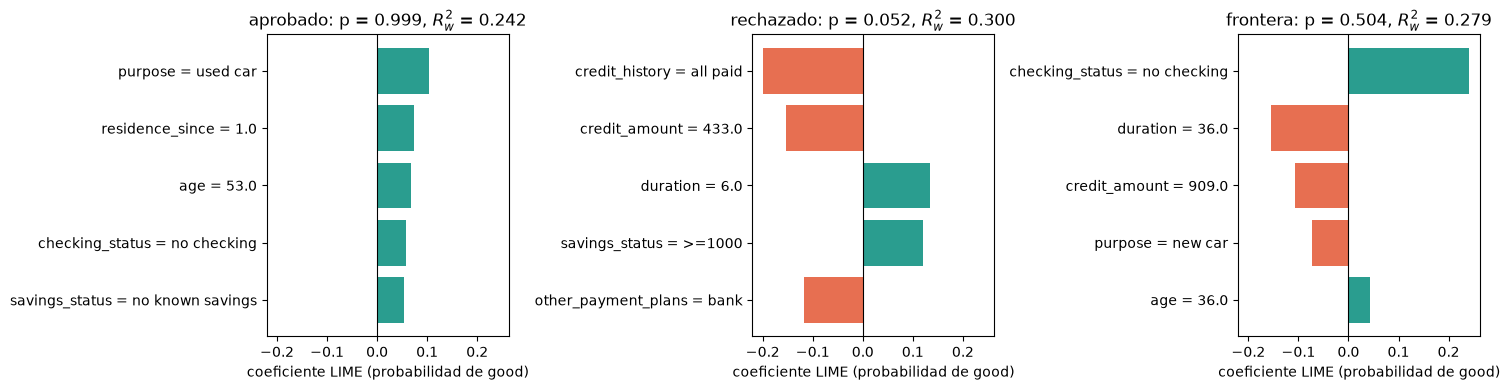

In [4]:
LIME_PARAMS = {'n_samples': 5000, 'k': 5, 'lam': 1.0, 'sigma_rel': 0.75, 'seed': SEED}

lime_results = {}
rows = []
for name, position in CLIENTS.items():
    result = lime_tabular(X_test.iloc[position].to_numpy(), **LIME_PARAMS)
    lime_results[name] = result
    for rank, (feature, coef) in enumerate(result['coef'].items(), start=1):
        rows.append({
            'cliente': name,
            'p_good': test_probability[position],
            'rango': rank,
            'variable': feature,
            'valor_cliente': X_test_raw.iloc[position][feature],
            'w_j': coef,
            'intercepto': result['intercept'],
            'R2_w': result['r2_w'],
        })

lime_31_df = pd.DataFrame(rows)
lime_31_df.to_csv(RESULTS_DIR / 'task3_1_lime_three_clients.csv', index=False)

summary_31 = pd.DataFrame([
    {
        'cliente': name,
        'p_good': test_probability[CLIENTS[name]],
        'intercepto': result['intercept'],
        'intercepto + suma de w_j': result['intercept'] + result['coef'].sum(),
        'R2_w': result['r2_w'],
        'N_ef': result['n_eff'],
    }
    for name, result in lime_results.items()
])

display(lime_31_df.drop(columns=['p_good', 'intercepto', 'R2_w']).style.format({'w_j': '{:+.4f}'}).hide(axis='index'))
display(summary_31.style.format(precision=4).hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, (name, result) in zip(axes, lime_results.items()):
    coef = result['coef'].iloc[::-1]
    labels = [f"{feature} = {X_test_raw.iloc[CLIENTS[name]][feature]}" for feature in coef.index]
    ax.barh(labels, coef.to_numpy(), color=np.where(coef.to_numpy() >= 0, '#2a9d8f', '#e76f51'))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{name}: p = {test_probability[CLIENTS[name]]:.3f}, $R^2_w$ = {result['r2_w']:.3f}")
    ax.set_xlabel('coeficiente LIME (probabilidad de good)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task3_1_lime_three_clients.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 3.1

Antes de interpretar comprobamos la implementación: nuestra solución cerrada coincide con `sklearn.linear_model.Ridge` con un error máximo de $2.8\times10^{-15}$ en los coeficientes y de $9.0\times10^{-15}$ en el intercepto. El intercepto **no se penalizó**.

| Cliente | $p(\text{good})$ | Variables conservadas y $w_j$ | Intercepto | $R^2_w$ |
|---|---:|---|---:|---:|
| Aprobado (índice 175) | 0.9994 | `purpose = used car` (+0.1033), `residence_since = 1` (+0.0732), `age = 53` (+0.0686), `checking_status = no checking` (+0.0567), `savings_status = no known savings` (+0.0537) | 0.7107 | **0.2425** |
| Rechazado (índice 721) | 0.0517 | `credit_history = all paid` (−0.1986), `credit_amount = 433` (−0.1544), `duration = 6` (+0.1335), `savings_status = >=1000` (+0.1203), `other_payment_plans = bank` (−0.1175) | 0.4912 | **0.2995** |
| Frontera (índice 164) | 0.5040 | `checking_status = no checking` (+0.2408), `duration = 36` (−0.1538), `credit_amount = 909` (−0.1064), `purpose = new car` (−0.0736), `age = 36` (+0.0438) | 0.6351 | **0.2790** |

**Lectura de los coeficientes.** En el cliente rechazado, conservar su `credit_history = all paid` en lugar de un historial tomado al azar baja la probabilidad de good unos 20 puntos, y su monto de 433 la baja otros 15. Su plazo corto de 6 meses y sus ahorros de al menos 1000 la suben unos 13 y 12 puntos, pero no alcanzan a compensar. En el cliente de frontera, no tener cuenta corriente (`no checking`) es lo que más lo ayuda (+0.24), mientras que el plazo de 36 meses lo perjudica (−0.15). Las variables que LIME señala para el rechazado y el aprobado se parecen a las principales de SHAP en el Task 2.2 (`credit_history`, `credit_amount` y `savings_status` en el rechazado; `purpose`, `age` y `checking_status` en el aprobado); en el Task 3.3 lo medimos formalmente.

**La fidelidad es baja en los tres clientes.** Con $K=5$, el modelo lineal explica solo entre el 24% y el 30% de la variación ponderada de la probabilidad en el vecindario. Se nota también al evaluar el modelo lineal en el propio cliente, con todas las variables presentes: el intercepto más la suma de los cinco coeficientes da 1.066 para el aprobado (una "probabilidad" mayor que 1) y 0.275 para el rechazado, cuya probabilidad real es 0.052. Es decir, el sustituto lineal acierta la dirección de los efectos, pero no reproduce bien el valor de la predicción que pretende explicar. Esto se debe a que el gradient boosting no es lineal ni aditivo en probabilidad: con unas 10 variables ausentes por muestra, las interacciones entre variables quedan fuera de un modelo de cinco términos. En el Task 3.3b vemos cuánto sube $R^2_w$ al aumentar $K$.

**Dos observaciones adicionales.** El tamaño efectivo de muestra es $N_{ef}=4808$ de 5000 en los tres clientes. Es el mismo número porque los pesos solo dependen de cuántas variables quedan ausentes, y con la misma semilla los tres clientes reciben los mismos vectores $z'$. Además, el cliente aprobado tiene clase real **bad**: el modelo le asigna 99.94% de probabilidad de good y se equivoca. LIME explica lo que hace el modelo, no si su decisión es correcta.

## Task 3.2: Estabilidad de LIME en el cliente rechazado

LIME es aleatorio: cada corrida sortea otros vectores $z'$ y otros valores de reemplazo, así que la explicación puede cambiar aunque el cliente y el modelo sean los mismos. Para medirlo ejecutamos LIME 20 veces con semillas distintas (de 42 a 61) en cada combinación de $N\in\{500, 2000, 5000\}$ y $\sigma_{rel}\in\{0.5, 0.75, 1.5\}$, manteniendo $K=5$ y $\lambda=1$.

En cada combinación calculamos:

- el **índice de Jaccard promedio** entre los conjuntos de las 5 variables principales de los $\binom{20}{2}=190$ pares de corridas, $J(A,B)=|A\cap B|/|A\cup B|$;
- el **tamaño efectivo de muestra promedio**, $N_{ef}=(\sum_n\pi_n)^2/\sum_n\pi_n^2$.

In [5]:
N_GRID = [500, 2000, 5000]
SIGMA_GRID = [0.5, 0.75, 1.5]
STABILITY_SEEDS = [SEED + r for r in range(20)]

def jaccard(a, b):
    return len(a & b) / len(a | b)

x_rejected = X_test.iloc[rejected_position].to_numpy()
run_rows, stability_rows = [], []
start = time.perf_counter()
for n_samples in N_GRID:
    for sigma_rel in SIGMA_GRID:
        top_sets, n_effs = [], []
        for seed in STABILITY_SEEDS:
            result = lime_tabular(x_rejected, n_samples=n_samples, k=5, lam=1.0, sigma_rel=sigma_rel, seed=seed)
            top_sets.append(frozenset(result['coef'].index))
            n_effs.append(result['n_eff'])
            run_rows.append({
                'N': n_samples, 'sigma_rel': sigma_rel, 'seed': seed,
                'top5': ', '.join(sorted(result['coef'].index)),
                'R2_w': result['r2_w'], 'N_ef': result['n_eff'],
            })
        pair_scores = [jaccard(a, b) for a, b in combinations(top_sets, 2)]
        stability_rows.append({
            'N': n_samples, 'sigma_rel': sigma_rel,
            'jaccard_mean': np.mean(pair_scores), 'jaccard_std': np.std(pair_scores),
            'n_eff_mean': np.mean(n_effs), 'n_eff_ratio': np.mean(n_effs) / n_samples,
            'distinct_top5_sets': len(set(top_sets)),
        })
elapsed = time.perf_counter() - start

runs_32_df = pd.DataFrame(run_rows)
stability_df = pd.DataFrame(stability_rows)
runs_32_df.to_csv(RESULTS_DIR / 'task3_2_runs.csv', index=False)
stability_df.to_csv(RESULTS_DIR / 'task3_2_stability.csv', index=False)

jaccard_table = stability_df.pivot(index='N', columns='sigma_rel', values='jaccard_mean')
n_eff_table = stability_df.pivot(index='N', columns='sigma_rel', values='n_eff_mean')
jaccard_table.columns.name = n_eff_table.columns.name = 'σ_rel'

print(f'{len(runs_32_df)} corridas de LIME en {elapsed:.1f} s')
print('Jaccard promedio (190 pares por celda)')
display(jaccard_table.style.format('{:.4f}'))
print('N_ef promedio (20 corridas por celda)')
display(n_eff_table.style.format('{:.1f}'))
print('Detalle por combinación')
display(stability_df.style.format({'jaccard_mean': '{:.4f}', 'jaccard_std': '{:.4f}', 'n_eff_mean': '{:.1f}', 'n_eff_ratio': '{:.4f}'}).hide(axis='index'))

180 corridas de LIME en 1.5 s
Jaccard promedio (190 pares por celda)


σ_rel,0.500000,0.750000,1.500000
N,,,
500,0.7927,0.8163,0.7915
2000,0.9368,0.9368,0.9368
5000,1.0000,1.0000,1.0000


N_ef promedio (20 corridas por celda)


σ_rel,0.500000,0.750000,1.500000
N,,,
500,409.7,480.5,498.8
2000,1639.4,1922.5,1995.1
5000,4099.9,4806.3,4987.6


Detalle por combinación


N,sigma_rel,jaccard_mean,jaccard_std,n_eff_mean,n_eff_ratio,distinct_top5_sets
500,0.500000,0.7927,0.1825,409.7,0.8194,7
500,0.750000,0.8163,0.1823,480.5,0.9610,7
500,1.500000,0.7915,0.1841,498.8,0.9975,7
2000,0.500000,0.9368,0.1306,1639.4,0.8197,2
2000,0.750000,0.9368,0.1306,1922.5,0.9612,2
2000,1.500000,0.9368,0.1306,1995.1,0.9975,2
5000,0.500000,1.0000,0.0000,4099.9,0.8200,1
5000,0.750000,1.0000,0.0000,4806.3,0.9613,1
5000,1.500000,1.0000,0.0000,4987.6,0.9975,1


### Respuesta 3.2

Ejecutamos 180 corridas de LIME (9 combinaciones × 20 semillas) sobre el cliente rechazado.

**Jaccard promedio entre las 5 variables principales (190 pares por celda)**

| $N$ \ $\sigma_{rel}$ | 0.5 | 0.75 | 1.5 |
|---:|---:|---:|---:|
| 500 | 0.7927 | 0.8163 | 0.7915 |
| 2000 | 0.9368 | 0.9368 | 0.9368 |
| 5000 | 1.0000 | 1.0000 | 1.0000 |

**$N_{ef}$ promedio (20 corridas por celda)**

| $N$ \ $\sigma_{rel}$ | 0.5 | 0.75 | 1.5 |
|---:|---:|---:|---:|
| 500 | 409.7 | 480.5 | 498.8 |
| 2000 | 1639.4 | 1922.5 | 1995.1 |
| 5000 | 4099.9 | 4806.3 | 4987.6 |

Con $N=500$ las 20 corridas producen 7 conjuntos distintos de variables principales, y el Jaccard ronda 0.80: en promedio, dos corridas comparten 4 de las 5 variables. Con $N=2000$ solo aparecen 2 conjuntos (18 de las 20 corridas coinciden) y con $N=5000$ las 20 corridas eligen exactamente las mismas cinco: `credit_history`, `credit_amount`, `duration`, `savings_status` y `other_payment_plans`. Cuatro de ellas (`credit_history`, `credit_amount`, `savings_status` y `duration`) aparecen en casi todas las corridas de cualquier combinación; la que cambia es la quinta, donde `other_payment_plans` compite con `checking_status` e `installment_commitment`.

El ancho del kernel casi no afecta la estabilidad. El cociente $N_{ef}/N$ depende solo de $\sigma_{rel}$ (0.82, 0.96 y 0.998) y no de $N$, pero incluso con $\sigma_{rel}=0.5$ se conserva el 82% de las muestras. La razón es que en cada muestra el número de variables ausentes se concentra alrededor de 10 (con 20 bits de probabilidad 0.5, el 95.9% de las muestras tiene entre 6 y 14 ausentes), de modo que el kernel da pesos parecidos a casi todas. Con $N=2000$ y $N=5000$ el Jaccard es idéntico en las tres columnas porque las mismas semillas generan las mismas muestras y el cambio de pesos no alcanza a reordenar las cinco variables. Analizamos la relación entre $N_{ef}$ y el Jaccard en el Task 3.5a.

## Task 3.3: LIME frente a SHAP

### 3.3a: Coincidencia entre rankings

Para cada cliente comparamos $|w_j|$ del ajuste de LIME sobre las 20 variables (antes de quedarnos con $K$) con $|\phi_j|$ de TreeSHAP intervencional del Task 2.2. Los dos métodos están en unidades distintas (LIME en probabilidad, SHAP en log-odds), por eso comparamos **rankings** con la correlación de Spearman y no los valores. También contamos cuántas de las tres variables principales coinciden.

In [6]:
comparison_rows, detail_frames = [], []
for name, position in CLIENTS.items():
    lime_abs = lime_results[name]['full_coef'].abs()
    shap_abs = pd.Series(np.abs(shap_values[position]), index=FEATURES)
    rho = spearmanr(lime_abs, shap_abs).statistic
    lime_top3 = lime_abs.sort_values(ascending=False).index[:3].tolist()
    shap_top3 = shap_abs.sort_values(ascending=False).index[:3].tolist()
    shared = [feature for feature in lime_top3 if feature in shap_top3]
    comparison_rows.append({
        'cliente': name,
        'spearman_|w|_vs_|phi|': rho,
        'top3_LIME': ', '.join(lime_top3),
        'top3_SHAP': ', '.join(shap_top3),
        'coinciden_top3': f'{len(shared)}/3',
    })
    detail_frames.append(pd.DataFrame({
        'cliente': name,
        'variable': FEATURES,
        'valor_cliente': [X_test_raw.iloc[position][f] for f in FEATURES],
        'w_LIME': lime_results[name]['full_coef'].to_numpy(),
        'phi_SHAP': shap_values[position],
        'rango_LIME': lime_abs.rank(ascending=False, method='min').astype(int).to_numpy(),
        'rango_SHAP': shap_abs.rank(ascending=False, method='min').astype(int).to_numpy(),
    }))

comparison_33_df = pd.DataFrame(comparison_rows)
detail_33_df = pd.concat(detail_frames, ignore_index=True)
detail_33_df['diferencia_rango'] = (detail_33_df['rango_LIME'] - detail_33_df['rango_SHAP']).abs()
detail_33_df['mismo_signo'] = np.sign(detail_33_df['w_LIME']) == np.sign(detail_33_df['phi_SHAP'])
comparison_33_df.to_csv(RESULTS_DIR / 'task3_3a_lime_vs_shap.csv', index=False)
detail_33_df.to_csv(RESULTS_DIR / 'task3_3a_lime_vs_shap_detail.csv', index=False)

display(comparison_33_df.style.format({'spearman_|w|_vs_|phi|': '{:.4f}'}).hide(axis='index'))
for name in CLIENTS:
    print(f'Cliente {name}: 8 variables principales según SHAP')
    view = detail_33_df[detail_33_df['cliente'] == name].sort_values('rango_SHAP').head(8)
    display(view.drop(columns='cliente').style.format({'w_LIME': '{:+.4f}', 'phi_SHAP': '{:+.4f}'}).hide(axis='index'))

cliente,spearman_|w|_vs_|phi|,top3_LIME,top3_SHAP,coinciden_top3
aprobado,0.7368,"purpose, residence_since, age","purpose, age, checking_status",2/3
rechazado,0.9519,"credit_history, credit_amount, duration","credit_history, savings_status, credit_amount",2/3
frontera,0.8692,"checking_status, duration, credit_amount","checking_status, duration, credit_amount",3/3


Cliente aprobado: 8 variables principales según SHAP


variable,valor_cliente,w_LIME,phi_SHAP,rango_LIME,rango_SHAP,diferencia_rango,mismo_signo
purpose,used car,+0.1043,+1.4633,1,1,0,True
age,53.000000,+0.0697,+1.1045,3,2,1,True
checking_status,no checking,+0.0575,+1.0069,4,3,1,True
residence_since,1.000000,+0.0729,+0.9492,2,4,2,True
savings_status,no known savings,+0.0529,+0.6710,5,5,0,True
duration,30.000000,+0.0417,+0.3832,6,6,0,True
job,high qualif/self emp/mgmt,+0.0194,+0.3366,7,7,0,True
other_payment_plans,bank,-0.0006,+0.2301,18,8,10,False


Cliente rechazado: 8 variables principales según SHAP


variable,valor_cliente,w_LIME,phi_SHAP,rango_LIME,rango_SHAP,diferencia_rango,mismo_signo
credit_history,all paid,-0.2002,-1.3162,1,1,0,True
savings_status,>=1000,+0.1216,+0.9721,4,2,2,True
credit_amount,433.000000,-0.1535,-0.9647,2,3,1,True
other_payment_plans,bank,-0.1127,-0.8519,5,4,1,True
duration,6.000000,+0.1315,+0.7121,3,5,2,True
checking_status,0<=X<200,-0.1002,-0.6177,6,6,0,True
purpose,education,-0.0681,-0.5619,8,7,1,True
residence_since,2.000000,-0.0780,-0.5359,7,8,1,True


Cliente frontera: 8 variables principales según SHAP


variable,valor_cliente,w_LIME,phi_SHAP,rango_LIME,rango_SHAP,diferencia_rango,mismo_signo
checking_status,no checking,+0.2412,+1.5109,1,1,0,True
duration,36.000000,-0.1547,-1.3543,2,2,0,True
credit_amount,909.000000,-0.1053,-0.6611,3,3,0,True
purpose,new car,-0.0734,-0.6073,4,4,0,True
age,36.000000,+0.0429,+0.2297,5,5,0,True
installment_commitment,4.000000,-0.0384,-0.1915,7,6,1,True
credit_history,existing paid,-0.0206,-0.1892,9,7,2,True
existing_credits,1.000000,-0.0109,-0.1185,14,8,6,True


### Respuesta 3.3a

| Cliente | Spearman $\lvert w\rvert$ vs $\lvert\phi\rvert$ | Top 3 LIME | Top 3 SHAP | Coinciden |
|---|---:|---|---|---:|
| Aprobado | 0.7368 | `purpose`, `residence_since`, `age` | `purpose`, `age`, `checking_status` | 2/3 |
| Rechazado | **0.9519** | `credit_history`, `credit_amount`, `duration` | `credit_history`, `savings_status`, `credit_amount` | 2/3 |
| Frontera | 0.8692 | `checking_status`, `duration`, `credit_amount` | `checking_status`, `duration`, `credit_amount` | **3/3** |

Los dos métodos coinciden bastante en los tres clientes. En el rechazado y el de frontera la correlación entre rankings es muy alta (0.95 y 0.87), y en el de frontera las cinco primeras variables están exactamente en el mismo orden. Cuando el top 3 no coincide, la diferencia está en variables vecinas del ranking: en el rechazado, `savings_status` es la segunda para SHAP y la cuarta para LIME; en el aprobado, `checking_status` es la tercera para SHAP y la cuarta para LIME. Además, en las variables principales de cada cliente el signo coincide: LIME y SHAP dicen lo mismo sobre si un valor empuja hacia good o hacia bad.

La correlación más baja es la del cliente aprobado (0.74). Ahí está también la mayor discrepancia de toda la comparación: `other_payment_plans = bank` es la octava variable para SHAP ($\phi=+0.230$ log-odds), pero LIME la pone en el puesto 18 con un coeficiente prácticamente nulo y de signo contrario ($w=-0.0006$). La analizamos en el Task 3.5b.

### 3.3b: Fidelidad según $K$ en el cliente rechazado

Repetimos LIME sobre el cliente rechazado con $K\in\{3, 5, 10, 20\}$, con la misma semilla y los mismos parámetros. Así las 5000 muestras y sus pesos son idénticos en las cuatro corridas y lo único que cambia es cuántas variables conserva el modelo lineal.

Probabilidad real del cliente rechazado: 0.0517


K,R2_w,prediccion_lineal_en_x,variables
3,0.2229,0.2748,"credit_history, credit_amount, duration"
5,0.2995,0.2745,"credit_history, credit_amount, duration, savings_status, other_payment_plans"
10,0.3631,0.1251,"credit_history, credit_amount, duration, savings_status, other_payment_plans, checking_status, residence_since, purpose, personal_status, employment"
20,0.3719,0.0440,"credit_history, credit_amount, duration, savings_status, other_payment_plans, checking_status, residence_since, purpose, personal_status, employment, installment_commitment, housing, age, property_magnitude, other_parties, own_telephone, foreign_worker, job, existing_credits, num_dependents"


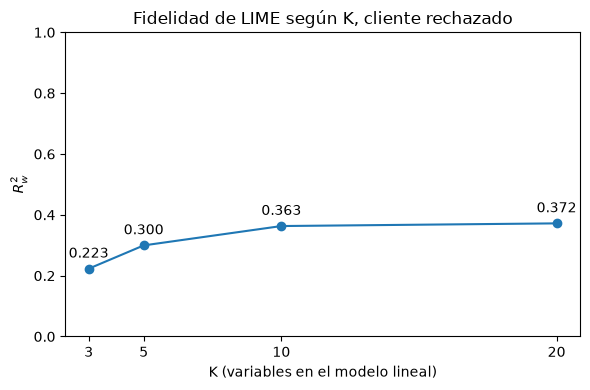

In [7]:
k_rows = []
for k in [3, 5, 10, 20]:
    result = lime_tabular(x_rejected, n_samples=5000, k=k, lam=1.0, sigma_rel=0.75, seed=SEED)
    k_rows.append({
        'K': k,
        'R2_w': result['r2_w'],
        'prediccion_lineal_en_x': result['intercept'] + result['coef'].sum(),
        'variables': ', '.join(result['coef'].index),
    })
k_df = pd.DataFrame(k_rows)
k_df.to_csv(RESULTS_DIR / 'task3_3b_r2_by_k.csv', index=False)
print(f'Probabilidad real del cliente rechazado: {test_probability[rejected_position]:.4f}')
display(k_df.style.format({'R2_w': '{:.4f}', 'prediccion_lineal_en_x': '{:.4f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_df['K'], k_df['R2_w'], marker='o')
for _, row in k_df.iterrows():
    ax.annotate(f"{row['R2_w']:.3f}", (row['K'], row['R2_w']), textcoords='offset points', xytext=(0, 8), ha='center')
ax.set_xticks(k_df['K'])
ax.set_xlabel('K (variables en el modelo lineal)')
ax.set_ylabel('$R^2_w$')
ax.set_title('Fidelidad de LIME según K, cliente rechazado')
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task3_3b_r2_by_k.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 3.3b

| $K$ | $R^2_w$ | Intercepto + $\sum w_j$ (predicción lineal en el cliente) |
|---:|---:|---:|
| 3 | 0.2229 | 0.2748 |
| 5 | 0.2995 | 0.2745 |
| 10 | 0.3631 | 0.1251 |
| 20 | 0.3719 | 0.0440 |

La probabilidad real del cliente rechazado es 0.0517.

La fidelidad sube con $K$, pero con rendimientos decrecientes: pasar de 3 a 5 variables suma 0.077, de 5 a 10 suma 0.064 y de 10 a 20 apenas 0.009. Incluso con las 20 variables, el mejor modelo lineal explica solo el 37% de la variación ponderada. Ese techo no se debe a que falten variables, sino a que el gradient boosting no es una suma de efectos independientes en probabilidad: tiene interacciones entre variables y la curvatura propia de pasar de log-odds a probabilidad, algo que ningún modelo lineal en $z'$ puede representar. Con $K=20$ la predicción lineal en el propio cliente (0.044) sí se acerca a la real (0.052), mientras que con $K\le5$ se queda en 0.27. Elegimos el valor de $K$ en el Task 3.5c.

## Task 3.4: Explicaciones contrafactuales para el cliente rechazado

Un contrafactual responde a la pregunta *¿qué tendría que cambiar este cliente para que el modelo lo apruebe?* Lo buscamos por muestreo con los valores del enunciado: 20 000 candidatos, como máximo 3 variables cambiadas por candidato y umbral de aprobación $\theta=0.5$.

- **Inmutables:** `age`, `personal_status` y `foreign_worker`. Nunca se modifican.
- **Accionables:** `duration`, `credit_amount`, `installment_commitment` (numéricas), `checking_status` y `savings_status` (categóricas). Son las únicas que pueden cambiar.
- **Resto de variables:** se quedan con el valor del cliente.

Cada candidato elige al azar cuántas variables cambiar (1, 2 o 3, con igual probabilidad) y cuáles. A cada variable elegida le asigna un valor tomado al azar de los observados en esa columna de entrenamiento, **excluyendo el valor actual del cliente**, para que toda variable marcada como cambiada cambie de verdad. Como el sorteo es sobre las filas de entrenamiento, los valores frecuentes salen más a menudo.

La distancia al original es

$$d(x,x')=\sum_{j\in\text{num}}\frac{|x_j-x'_j|}{\text{MAD}_j}+\sum_{j\in\text{cat}}\mathbb{1}[x_j\neq x'_j],$$

con $\text{MAD}_j$ la desviación absoluta mediana de la variable en entrenamiento; si es cero usamos la desviación absoluta media.

In [8]:
N_CANDIDATES = 20_000
MAX_CHANGES = 3
THETA = 0.5
IMMUTABLE = ['age', 'personal_status', 'foreign_worker']
ACTIONABLE = ['duration', 'credit_amount', 'installment_commitment', 'checking_status', 'savings_status']
assert not set(IMMUTABLE) & set(ACTIONABLE)

# Escala de cada variable numérica: MAD, o desviación absoluta media si el MAD es cero.
scale_rows = []
for feature in numeric_columns:
    column = X_train[feature]
    mad = float(np.median(np.abs(column - column.median())))
    mean_abs_dev = float(np.mean(np.abs(column - column.mean())))
    scale_rows.append({'variable': feature, 'MAD': mad, 'desv_abs_media': mean_abs_dev,
                       'escala_usada': mad if mad > 0 else mean_abs_dev})
scale_df = pd.DataFrame(scale_rows)
SCALE = dict(zip(scale_df['variable'], scale_df['escala_usada']))

def counterfactual_distance(original, candidates):
    '''Distancia d(x, x') para una matriz de candidatos codificados (filas) frente al original.'''
    distance = np.zeros(len(candidates))
    for j, feature in enumerate(FEATURES):
        if feature in categorical_columns:
            distance += candidates[:, j] != original[j]
        else:
            distance += np.abs(candidates[:, j] - original[j]) / SCALE[feature]
    return distance

def decode(feature, value):
    if feature in categorical_columns:
        return encoder.categories_[categorical_columns.index(feature)][int(value)]
    return float(value)

def generate_candidates(original, n_candidates, max_changes, seed):
    rng = np.random.default_rng(seed)
    candidates = np.tile(original, (n_candidates, 1))
    changed_sets = []
    # Valores observados en entrenamiento distintos al del cliente, por variable accionable.
    pools = {f: X_train[f].to_numpy()[X_train[f].to_numpy() != original[FEATURES.index(f)]] for f in ACTIONABLE}
    for row in range(n_candidates):
        n_changes = rng.integers(1, max_changes + 1)
        chosen = sorted(rng.choice(ACTIONABLE, size=n_changes, replace=False), key=ACTIONABLE.index)
        for feature in chosen:
            candidates[row, FEATURES.index(feature)] = rng.choice(pools[feature])
        changed_sets.append(tuple(chosen))
    return candidates, changed_sets

def search_counterfactuals(original, max_changes, seed=SEED):
    candidates, changed_sets = generate_candidates(original, N_CANDIDATES, max_changes, seed)
    probability = predict_good(candidates)
    frame = pd.DataFrame({
        'variables_cambiadas': changed_sets,
        'n_cambios': [len(s) for s in changed_sets],
        'p_good': probability,
        'distancia': counterfactual_distance(original, candidates),
    })
    frame['valido'] = frame['p_good'] >= THETA
    return candidates, frame

candidates, candidates_df = search_counterfactuals(x_rejected, MAX_CHANGES)
max_changes_used = MAX_CHANGES
if not candidates_df['valido'].any():
    max_changes_used = 5
    candidates, candidates_df = search_counterfactuals(x_rejected, max_changes_used)

# Las variables inmutables nunca deben cambiar.
for feature in IMMUTABLE:
    assert np.all(candidates[:, FEATURES.index(feature)] == x_rejected[FEATURES.index(feature)])

print(f'Máximo de variables cambiadas usado: {max_changes_used}')
print(f"Candidatos válidos (p_good >= {THETA}): {candidates_df['valido'].sum()} de {len(candidates_df)}")
display(scale_df.style.format(precision=3).hide(axis='index'))

Máximo de variables cambiadas usado: 3
Candidatos válidos (p_good >= 0.5): 171 de 20000


variable,MAD,desv_abs_media,escala_usada
duration,6.000,9.522,6.000
credit_amount,1057.500,1996.763,1057.500
installment_commitment,1.000,0.971,1.000
residence_since,1.000,1.008,1.000
age,7.000,8.968,7.000
existing_credits,0.000,0.514,0.514
num_dependents,0.000,0.274,0.274


### Selección de los tres contrafactuales

Entre los candidatos válidos tomamos el de menor distancia. Luego elegimos dos más: en cada paso, el de menor distancia cuyo conjunto de variables cambiadas sea distinto de los ya elegidos. Así los tres contrafactuales proponen caminos diferentes y no tres variantes del mismo cambio.

In [9]:
valid_df = candidates_df[candidates_df['valido']].sort_values('distancia')
selected_ids, used_sets = [], []
for candidate_id, row in valid_df.iterrows():
    changed = frozenset(row['variables_cambiadas'])
    if changed not in used_sets:
        selected_ids.append(candidate_id)
        used_sets.append(changed)
    if len(selected_ids) == 3:
        break

cf_rows = []
for number, candidate_id in enumerate(selected_ids, start=1):
    row = candidates_df.loc[candidate_id]
    for feature in row['variables_cambiadas']:
        j = FEATURES.index(feature)
        cf_rows.append({
            'contrafactual': number,
            'variable': feature,
            'valor_original': decode(feature, x_rejected[j]),
            'valor_nuevo': decode(feature, candidates[candidate_id, j]),
            'distancia': row['distancia'],
            'p_good': row['p_good'],
        })
counterfactuals_df = pd.DataFrame(cf_rows)
counterfactuals_df.to_csv(RESULTS_DIR / 'task3_4_counterfactuals.csv', index=False)

selected_df = candidates_df.loc[selected_ids]
metrics_34 = pd.DataFrame([
    {'conjunto': 'tres contrafactuales elegidos',
     'validez': candidates_df['valido'].mean(),
     'proximidad_promedio': selected_df['distancia'].mean(),
     'dispersion_promedio': selected_df['n_cambios'].mean()},
    {'conjunto': 'todos los candidatos válidos',
     'validez': candidates_df['valido'].mean(),
     'proximidad_promedio': valid_df['distancia'].mean(),
     'dispersion_promedio': valid_df['n_cambios'].mean()},
])
metrics_34.to_csv(RESULTS_DIR / 'task3_4_metrics.csv', index=False)

print(f'Probabilidad original del cliente rechazado: {test_probability[rejected_position]:.4f}')
display(counterfactuals_df.style.format({'distancia': '{:.4f}', 'p_good': '{:.4f}'}).hide(axis='index'))
display(metrics_34.style.format({'validez': '{:.4%}', 'proximidad_promedio': '{:.4f}', 'dispersion_promedio': '{:.2f}'}).hide(axis='index'))

# Cómo se reparten los válidos según el número de variables cambiadas y qué variables aparecen.
by_changes = candidates_df.groupby('n_cambios')['valido'].agg(['sum', 'count', 'mean'])
by_changes.columns = ['validos', 'candidatos', 'fraccion_valida']
presence = pd.Series({f: valid_df['variables_cambiadas'].apply(lambda s: f in s).mean() for f in ACTIONABLE},
                     name='fraccion_de_validos_que_la_cambian')
display(by_changes.style.format({'fraccion_valida': '{:.4%}'}))
display(presence.to_frame().style.format('{:.2%}'))

Probabilidad original del cliente rechazado: 0.0517


contrafactual,variable,valor_original,valor_nuevo,distancia,p_good
1,credit_amount,433.000000,392.000000,1.0388,0.7770
1,checking_status,0<=X<200,no checking,1.0388,0.7770
2,duration,6.000000,9.000000,1.5454,0.6080
2,credit_amount,433.000000,385.000000,1.5454,0.6080
2,checking_status,0<=X<200,no checking,1.5454,0.6080
3,credit_amount,433.000000,426.000000,2.0066,0.7630
3,installment_commitment,4.000000,3.000000,2.0066,0.7630
3,checking_status,0<=X<200,no checking,2.0066,0.7630


conjunto,validez,proximidad_promedio,dispersion_promedio
tres contrafactuales elegidos,0.8550%,1.5303,2.67
todos los candidatos válidos,0.8550%,3.5804,2.79


,validos,candidatos,fraccion_valida
n_cambios,,,
1,0,6729,0.0000%
2,36,6648,0.5415%
3,135,6623,2.0384%


,fraccion_de_validos_que_la_cambian
duration,4.68%
credit_amount,100.00%
installment_commitment,77.19%
checking_status,95.32%
savings_status,1.75%


### Diagnóstico: por qué todos los contrafactuales tocan `credit_amount`

El 100% de los candidatos válidos cambia `credit_amount`, y el primer contrafactual solo lo baja de 433 a 392. Para entenderlo variamos únicamente el monto del cliente rechazado, con su `checking_status` original y con `no checking`, y revisamos los clientes de entrenamiento con montos cercanos a 433.

monto,p_good_checking_original,p_good_no_checking
392,0.4564,0.7770
409,0.4564,0.7770
420,0.4137,0.7454
430,0.3125,0.6535
431,0.0517,0.1853
433,0.0517,0.1853
451,0.0517,0.1853
452,0.2491,0.5959
500,0.2060,0.5355
1000,0.1702,0.5137


Clientes de entrenamiento con monto entre 380 y 520


,credit_amount,duration,checking_status,credit_history,clase
590,385.0,12.0,<0,critical/other existing credit,good
111,392.0,15.0,>=200,existing paid,good
26,426.0,6.0,no checking,no credits/all paid,good
750,428.0,6.0,<0,existing paid,good
249,433.0,18.0,no checking,existing paid,bad
471,448.0,6.0,<0,existing paid,bad
964,454.0,6.0,0<=X<200,existing paid,good
39,458.0,9.0,0<=X<200,existing paid,good
811,484.0,6.0,0<=X<200,existing paid,good
451,518.0,6.0,no checking,existing paid,good


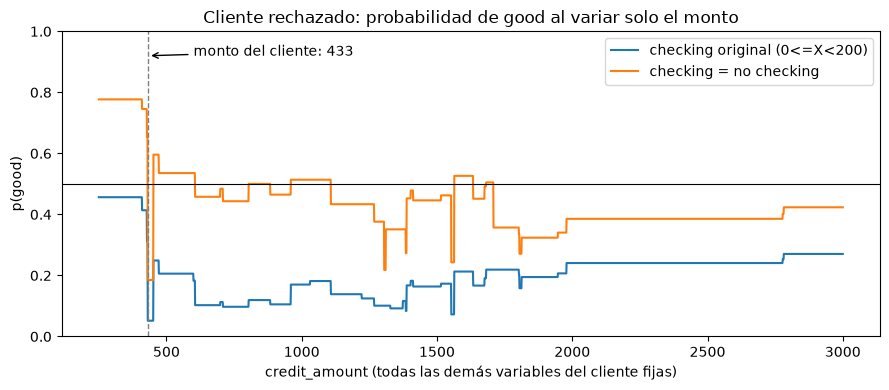

In [10]:
j_amount = FEATURES.index('credit_amount')
j_checking = FEATURES.index('checking_status')
no_checking_code = list(encoder.categories_[categorical_columns.index('checking_status')]).index('no checking')

amount_grid = np.arange(250, 3001, 1.0)
curves = {}
for label, checking_code in [('checking original (0<=X<200)', x_rejected[j_checking]), ('checking = no checking', no_checking_code)]:
    grid_rows = np.tile(x_rejected, (len(amount_grid), 1))
    grid_rows[:, j_amount] = amount_grid
    grid_rows[:, j_checking] = checking_code
    curves[label] = predict_good(grid_rows)

def p_at(amount, checking_code):
    row = x_rejected.copy()
    row[j_amount], row[j_checking] = amount, checking_code
    return predict_good(row[None])[0]

probe_df = pd.DataFrame([
    {'monto': amount,
     'p_good_checking_original': p_at(amount, x_rejected[j_checking]),
     'p_good_no_checking': p_at(amount, no_checking_code)}
    for amount in [392, 409, 420, 430, 431, 433, 451, 452, 500, 1000, 2000]
])
display(probe_df.style.format(precision=4).hide(axis='index'))

near = X_train_raw[(X_train_raw['credit_amount'] >= 380) & (X_train_raw['credit_amount'] <= 520)]
print('Clientes de entrenamiento con monto entre 380 y 520')
display(near[['credit_amount', 'duration', 'checking_status', 'credit_history']]
        .assign(clase=y_train.loc[near.index].map({1: 'good', 0: 'bad'}))
        .sort_values('credit_amount'))

fig, ax = plt.subplots(figsize=(9, 4))
for label, values in curves.items():
    ax.plot(amount_grid, values, label=label)
ax.axvline(433, color='gray', linestyle='--', linewidth=1)
ax.axhline(THETA, color='black', linewidth=0.8)
ax.annotate('monto del cliente: 433', (433, 0.92), xytext=(600, 0.92), arrowprops={'arrowstyle': '->'})
ax.set_xlabel('credit_amount (todas las demás variables del cliente fijas)')
ax.set_ylabel('p(good)')
ax.set_title('Cliente rechazado: probabilidad de good al variar solo el monto')
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task3_4_amount_curve.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 3.4

Con 20 000 candidatos y un máximo de **3** variables cambiadas encontramos 171 candidatos válidos, así que no fue necesario subir el máximo a 5. El cliente parte de $p(\text{good})=0.0517$.

| CF | Variables cambiadas | Original | Nuevo | Distancia | $p(\text{good})$ |
|---:|---|---|---|---:|---:|
| 1 | `credit_amount` | 433 | 392 | 1.0388 | 0.7770 |
|   | `checking_status` | 0<=X<200 | no checking | | |
| 2 | `duration` | 6 | 9 | 1.5454 | 0.6080 |
|   | `credit_amount` | 433 | 385 | | |
|   | `checking_status` | 0<=X<200 | no checking | | |
| 3 | `credit_amount` | 433 | 426 | 2.0066 | 0.7630 |
|   | `installment_commitment` | 4 | 3 | | |
|   | `checking_status` | 0<=X<200 | no checking | | |

| Métrica | Tres contrafactuales elegidos | Todos los válidos |
|---|---:|---:|
| Validez (fracción de candidatos válidos) | 0.855% (171 de 20 000) | 0.855% |
| Proximidad promedio (distancia) | 1.5303 | 3.5804 |
| Dispersión promedio (variables cambiadas) | 2.67 | 2.79 |

Ningún candidato que cambia una sola variable es válido (0 de 6 729); con dos variables lo es el 0.54% y con tres el 2.04%. Hay dos variables casi obligatorias: el **100%** de los válidos cambia `credit_amount` y el **95.3%** cambia `checking_status` a `no checking`. Las otras aparecen poco (`installment_commitment` en el 77.2%, `duration` en el 4.7% y `savings_status` en el 1.8%).

**Los contrafactuales aprovechan un artefacto del modelo.** El primer contrafactual pide bajar el monto apenas 41 unidades (de 433 a 392). La curva de probabilidad al variar solo el monto muestra por qué: el cliente cae en un valle muy angosto entre 431 y 451, donde la probabilidad es la más baja de todo el rango (0.0517 con su cuenta corriente y 0.1853 con `no checking`). Fuera de ese valle sube de golpe: 0.4564 con 409 o menos y 0.2491 con 452. En entrenamiento hay dos clientes **bad** justo con montos de 433 y 448, rodeados de clientes good (385, 392, 426, 428, 454, 458, 484, 518); los árboles aprendieron cortes en 430.5 y 451 para aislarlos. Es un sobreajuste local, no una regla de riesgo con sentido económico: nadie diría que pedir 392 es mucho menos riesgoso que pedir 433. Un contrafactual como "pida 41 menos y abra la cuenta de otra forma" es válido para el modelo, pero no es un consejo útil para la persona, y muestra lo fácil que es manipular la decisión con cambios mínimos. Retomamos esto en el Task 3.5d y en el Task 4.3c.

## Task 3.5: Análisis

### 3.5a: Relación entre $N_{ef}$ y el Jaccard, y muestras necesarias para $J=0.9$

Primero medimos por qué cambian las cinco variables principales: comparamos la separación entre la quinta y la sexta variable con la variación de sus coeficientes entre semillas. Luego extrapolamos el $N$ necesario para un Jaccard de 0.9 con $\sigma_{rel}=0.75$ y lo verificamos con corridas adicionales.

Quinta: other_payment_plans |w| = 0.1127 | sexta: checking_status |w| = 0.1002 | separación = 0.0125


N,sd_w_other_payment_plans,sd_w_checking_status,jaccard_sigma_0.75
500,0.0206,0.0174,0.8163
2000,0.0159,0.0109,0.9368
5000,0.0076,0.0058,1.0000


Estimación con 1 - J ∝ N^(-1/2): N ≈ 1687
Estimación con potencia ajustada (exponente 0.770): N ≈ 1101


N,jaccard_20_semillas,jaccard_50_semillas
500,0.8163,0.7615
750,0.8223,0.8356
1000,1.0000,0.9019
1100,0.9070,0.8447
1250,1.0000,0.9141
1500,0.9105,0.9258
1700,0.9125,0.9616
2000,0.9368,0.9611


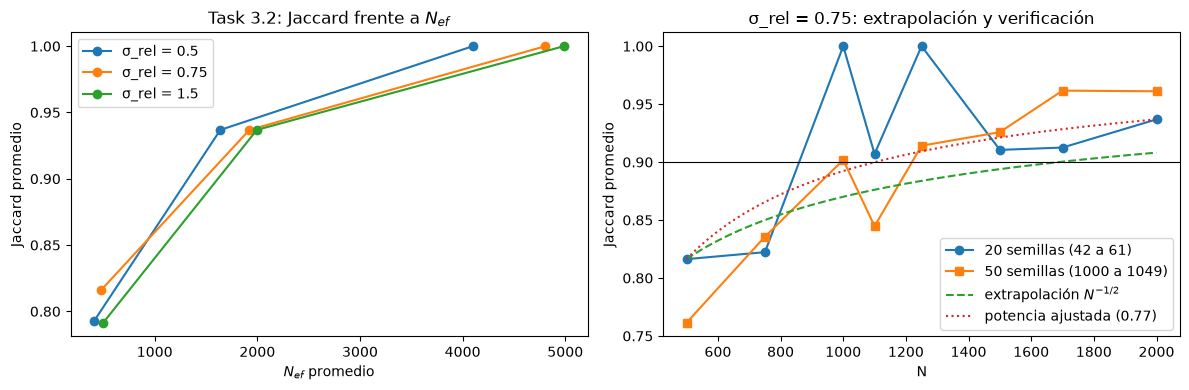

In [11]:
def mean_jaccard(n_samples, seeds, sigma_rel=0.75):
    sets = [frozenset(lime_tabular(x_rejected, n_samples=n_samples, sigma_rel=sigma_rel, seed=s)['coef'].index) for s in seeds]
    return float(np.mean([jaccard(a, b) for a, b in combinations(sets, 2)]))

# Separación entre la quinta y la sexta variable (N = 5000, semilla 42).
ranked = lime_tabular(x_rejected)['full_coef'].abs().sort_values(ascending=False)
gap_5_6 = ranked.iloc[4] - ranked.iloc[5]
print(f'Quinta: {ranked.index[4]} |w| = {ranked.iloc[4]:.4f} | sexta: {ranked.index[5]} |w| = {ranked.iloc[5]:.4f} | separación = {gap_5_6:.4f}')

# Variación de los coeficientes de esas dos variables entre las 20 semillas del Task 3.2.
sd_rows = []
for n_samples in N_GRID:
    coefs = pd.DataFrame([lime_tabular(x_rejected, n_samples=n_samples, seed=s)['full_coef'] for s in STABILITY_SEEDS])
    sd_rows.append({'N': n_samples,
                    f'sd_w_{ranked.index[4]}': coefs[ranked.index[4]].std(),
                    f'sd_w_{ranked.index[5]}': coefs[ranked.index[5]].std(),
                    'jaccard_sigma_0.75': jaccard_table.loc[n_samples, 0.75]})
display(pd.DataFrame(sd_rows).style.format(precision=4).hide(axis='index'))

# Extrapolación desde la tabla del Task 3.2 (sigma_rel = 0.75).
j500, j2000 = jaccard_table.loc[500, 0.75], jaccard_table.loc[2000, 0.75]
n_sqrt = 500 * ((1 - j500) / (1 - 0.9)) ** 2                       # supuesto 1 - J ∝ N^(-1/2)
exponent = np.log((1 - j500) / (1 - j2000)) / np.log(2000 / 500)  # potencia ajustada con dos puntos
n_power = 500 * ((1 - j500) / (1 - 0.9)) ** (1 / exponent)
print(f'Estimación con 1 - J ∝ N^(-1/2): N ≈ {n_sqrt:.0f}')
print(f'Estimación con potencia ajustada (exponente {exponent:.3f}): N ≈ {n_power:.0f}')

# Verificación: mismas 20 semillas del Task 3.2 y una repetición con 50 semillas nuevas.
VERIFY_N = [500, 750, 1000, 1100, 1250, 1500, 1700, 2000]
NEW_SEEDS = [1000 + r for r in range(50)]
verify_df = pd.DataFrame([
    {'N': n, 'jaccard_20_semillas': mean_jaccard(n, STABILITY_SEEDS), 'jaccard_50_semillas': mean_jaccard(n, NEW_SEEDS)}
    for n in VERIFY_N
])
verify_df.to_csv(RESULTS_DIR / 'task3_5a_verification.csv', index=False)
display(verify_df.style.format({'jaccard_20_semillas': '{:.4f}', 'jaccard_50_semillas': '{:.4f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sigma_rel in SIGMA_GRID:
    subset = stability_df[stability_df['sigma_rel'] == sigma_rel]
    axes[0].plot(subset['n_eff_mean'], subset['jaccard_mean'], marker='o', label=f'σ_rel = {sigma_rel}')
axes[0].set_xlabel('$N_{ef}$ promedio')
axes[0].set_ylabel('Jaccard promedio')
axes[0].set_title('Task 3.2: Jaccard frente a $N_{ef}$')
axes[0].legend()
axes[1].plot(verify_df['N'], verify_df['jaccard_20_semillas'], marker='o', label='20 semillas (42 a 61)')
axes[1].plot(verify_df['N'], verify_df['jaccard_50_semillas'], marker='s', label='50 semillas (1000 a 1049)')
grid_n = np.linspace(500, 2000, 200)
axes[1].plot(grid_n, 1 - (1 - j500) * (grid_n / 500) ** -0.5, linestyle='--', label='extrapolación $N^{-1/2}$')
axes[1].plot(grid_n, 1 - (1 - j500) * (grid_n / 500) ** -exponent, linestyle=':', label=f'potencia ajustada ({exponent:.2f})')
axes[1].axhline(0.9, color='black', linewidth=0.8)
axes[1].set_xlabel('N')
axes[1].set_ylabel('Jaccard promedio')
axes[1].set_title('σ_rel = 0.75: extrapolación y verificación')
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task3_5a_jaccard.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 3.5a

En nuestras tablas el Jaccard sube con $N$ (0.79 a 0.82 con $N=500$, 0.94 con 2000 y 1.00 con 5000) y $N_{ef}$ también, porque $N_{ef}/N$ es fijo para cada $\sigma_{rel}$ (0.82, 0.96 y 0.998). Pero dentro de una misma fila $N_{ef}$ cambia bastante (de 1639 a 1995 con $N=2000$) y el Jaccard no se mueve (0.9368 en las tres columnas). Por eso $N_{ef}$ no es lo que decide la estabilidad en este caso. Lo que la decide es si el ruido de muestreo de los coeficientes es menor que la separación entre la quinta y la sexta variable. Con $N=5000$, la quinta (`other_payment_plans`, $|w|=0.1127$) supera a la sexta (`checking_status`, $|w|=0.1002$) por **0.0125**, y la desviación estándar de esos coeficientes entre semillas es 0.0076 y 0.0058, así que no se cruzan. Con $N=500$ esa desviación es 0.0206 y 0.0174, mayor que la separación, y las variables cambian de lugar. En el gráfico de la izquierda se ve que las tres curvas de $\sigma_{rel}$ casi se superponen: a igual $N$ dan el mismo Jaccard aunque tengan $N_{ef}$ distinto.

**Extrapolación.** El error de un coeficiente de regresión decrece como $1/\sqrt{N}$, así que suponemos $1-J\propto N^{-1/2}$. Con $N=500$ tenemos $1-J=0.184$, y para bajar a $1-J=0.10$ se necesitan $N\approx500\cdot(0.184/0.10)^2\approx$ **1,687** muestras. Si en cambio ajustamos una potencia con los dos puntos medidos (500 y 2000), el exponente sale 0.770 y la estimación es **1,101**. Esperamos entonces el umbral entre unas 1,100 y 1,700 muestras.

**Verificación.** Con las mismas 20 semillas del Task 3.2 obtuvimos $J=0.907$ con $N=1100$ y $J=0.913$ con $N=1700$: las dos estimaciones superan 0.9. Como el promedio de 20 corridas es ruidoso (con $N=1000$ y $N=1250$ dio 1.000 por casualidad), repetimos con 50 semillas nuevas: $N=1000$ da 0.902, $N=1250$ da 0.914, $N=1500$ da 0.926 y $N=1700$ da 0.962, aunque $N=1100$ dio 0.845. Concluimos que el Jaccard de 0.9 se alcanza alrededor de 1,000 a 1,500 muestras, y que para tener margen usaríamos $N\ge1{,}500$. La propia verificación muestra que medir la estabilidad con pocas corridas también tiene incertidumbre.

### 3.5b: Mayor discrepancia entre LIME y SHAP

Buscamos la variable con mayor diferencia de ranking entre $|w|$ de LIME y $|\phi|$ de SHAP en los tres clientes y ponemos a prueba la hipótesis de **saturación**: si el cliente tiene una probabilidad muy cercana a 1, un cambio grande en log-odds (la escala de SHAP) casi no se refleja en la probabilidad (la escala de LIME). Hacemos tres pruebas: variamos solo esa variable en el cliente, reducimos $\sigma_{rel}$ y ejecutamos LIME sobre la salida en log-odds.

Mayor discrepancia: cliente aprobado, variable other_payment_plans = bank
  rango LIME 18 (w = -0.0006) | rango SHAP 8 (phi = +0.2301)


categoria,p_good,log_odds,frecuencia_entrenamiento
bank,0.99945,7.4990,0.130
none,0.99785,6.1396,0.819
stores,0.99853,6.5232,0.051


Muestras de LIME: p media con la variable presente 0.8859, ausente 0.8864
Probabilidad de las muestras de LIME (percentiles 5, 50 y 95): [0.4687 0.9642 0.9978]


sigma_rel,w,rango_LIME,R2_w
0.250000,+0.00657,9,0.2175
0.500000,+0.00164,15,0.2457
0.750000,-0.00058,18,0.2425
1.500000,-0.00214,17,0.2401


cliente,spearman_LIME_prob,spearman_LIME_logodds,rango_other_payment_plans_logodds,w_other_payment_plans_logodds,phi_other_payment_plans
aprobado,0.7368,0.8391,8,0.2362,0.2301
rechazado,0.9519,0.9444,5,-0.7984,-0.8519
frontera,0.8692,0.8586,7,0.2352,0.1041


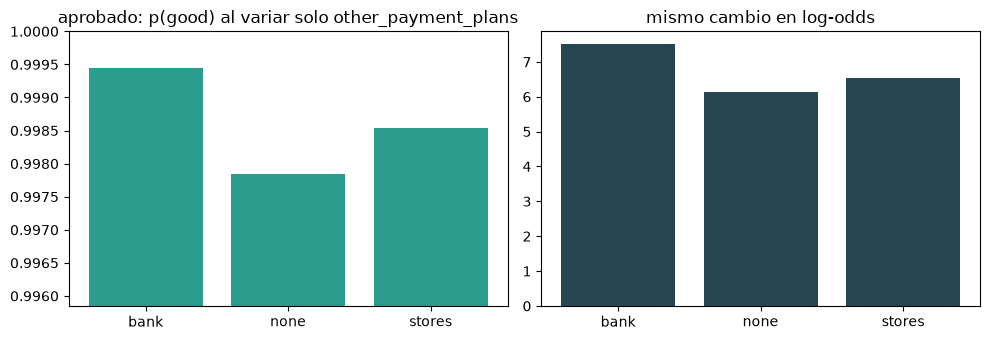

In [12]:
from scipy.special import logit

worst = detail_33_df.sort_values('diferencia_rango', ascending=False).iloc[0]
disc_client, disc_feature = worst['cliente'], worst['variable']
disc_position = CLIENTS[disc_client]
x_disc = X_test.iloc[disc_position].to_numpy()
j_disc = FEATURES.index(disc_feature)
print(f"Mayor discrepancia: cliente {disc_client}, variable {disc_feature} = {worst['valor_cliente']}")
print(f"  rango LIME {worst['rango_LIME']} (w = {worst['w_LIME']:+.4f}) | rango SHAP {worst['rango_SHAP']} (phi = {worst['phi_SHAP']:+.4f})")

# Prueba 1: variar solo esa variable en el cliente.
categories = encoder.categories_[categorical_columns.index(disc_feature)]
single_rows = []
for code_value, category in enumerate(categories):
    row = x_disc.copy()
    row[j_disc] = code_value
    p = predict_good(row[None])[0]
    single_rows.append({'categoria': category, 'p_good': p, 'log_odds': logit(p),
                        'frecuencia_entrenamiento': (X_train_raw[disc_feature] == category).mean()})
single_df = pd.DataFrame(single_rows)
display(single_df.style.format({'p_good': '{:.5f}', 'log_odds': '{:.4f}', 'frecuencia_entrenamiento': '{:.3f}'}).hide(axis='index'))

base_result = lime_results[disc_client]
present = base_result['Z_binary'][:, j_disc] == 1
print(f"Muestras de LIME: p media con la variable presente {base_result['target'][present].mean():.4f}, ausente {base_result['target'][~present].mean():.4f}")
print(f"Probabilidad de las muestras de LIME (percentiles 5, 50 y 95): {np.quantile(base_result['target'], [0.05, 0.5, 0.95]).round(4)}")

# Prueba 2: reducir sigma_rel.
def rank_of(coef, feature):
    return int(coef.abs().rank(ascending=False, method='min')[feature])

sigma_rows = []
for sigma_rel in [0.25, 0.5, 0.75, 1.5]:
    result = lime_tabular(x_disc, sigma_rel=sigma_rel)
    sigma_rows.append({'sigma_rel': sigma_rel, 'w': result['full_coef'][disc_feature],
                       'rango_LIME': rank_of(result['full_coef'], disc_feature), 'R2_w': result['r2_w']})
display(pd.DataFrame(sigma_rows).style.format({'w': '{:+.5f}', 'R2_w': '{:.4f}'}).hide(axis='index'))

# Prueba 3: LIME sobre la salida en log-odds (la misma escala de SHAP).
def predict_log_odds(rows):
    return model.decision_function(pd.DataFrame(rows, columns=FEATURES))

scale_rows = []
for name, position in CLIENTS.items():
    shap_abs = np.abs(shap_values[position])
    on_prob = lime_results[name]
    on_logodds = lime_tabular(X_test.iloc[position].to_numpy(), predict=predict_log_odds)
    scale_rows.append({
        'cliente': name,
        'spearman_LIME_prob': spearmanr(on_prob['full_coef'].abs(), shap_abs).statistic,
        'spearman_LIME_logodds': spearmanr(on_logodds['full_coef'].abs(), shap_abs).statistic,
        f'rango_{disc_feature}_logodds': rank_of(on_logodds['full_coef'], disc_feature),
        f'w_{disc_feature}_logodds': on_logodds['full_coef'][disc_feature],
        f'phi_{disc_feature}': shap_values[position, j_disc],
    })
scale_df = pd.DataFrame(scale_rows)
scale_df.to_csv(RESULTS_DIR / 'task3_5b_logodds.csv', index=False)
display(scale_df.style.format(precision=4).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(single_df['categoria'], single_df['p_good'], color='#2a9d8f')
axes[0].set_ylim(single_df['p_good'].min() - 0.002, 1.0)
axes[0].set_title(f'{disc_client}: p(good) al variar solo {disc_feature}')
axes[1].bar(single_df['categoria'], single_df['log_odds'], color='#264653')
axes[1].set_title('mismo cambio en log-odds')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task3_5b_saturation.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 3.5b

La mayor discrepancia es la del **cliente aprobado** en `other_payment_plans = bank`: SHAP la pone en el puesto 8 ($\phi=+0.2301$ log-odds) y LIME en el 18, con un coeficiente prácticamente nulo y de signo contrario ($w=-0.0006$).

**Hipótesis: saturación de la sigmoide.** El cliente tiene $p=0.9994$. En esa zona la curva logística es casi plana, de modo que un cambio grande en log-odds apenas mueve la probabilidad. SHAP mide en log-odds y LIME en probabilidad.

- **Variar solo esa variable.** Con `bank`, $p=0.99945$ (log-odds 7.499); con `none`, $p=0.99785$ (6.140); con `stores`, $p=0.99853$ (6.523). Pasar de `bank` a `none`, que es lo que ocurre en la mayoría de las muestras de LIME porque `none` es el 81.9% de entrenamiento, cambia los log-odds en **1.36** pero la probabilidad solo en **0.0016**. En las muestras de LIME la probabilidad media es 0.8859 con la variable presente y 0.8864 con la variable ausente: en probabilidad no hay efecto que detectar.
- **Reducir $\sigma_{rel}$.** La variable sube del puesto 18 al 15 con $\sigma_{rel}=0.5$ y al 9 con $\sigma_{rel}=0.25$, pero su coeficiente sigue siendo diminuto (+0.0066). La localidad ayuda poco.
- **LIME sobre log-odds.** Al explicar la salida en log-odds, `other_payment_plans` pasa al **puesto 8 con $w=+0.2362$**, casi igual al $\phi=+0.2301$ de SHAP, y el Spearman del cliente aprobado sube de 0.737 a **0.839**. En el rechazado y en el de frontera, que no están en una zona saturada, el Spearman casi no cambia (0.952 → 0.944 y 0.869 → 0.859).

**Conclusión.** La discrepancia se debe a una **relación no lineal**: la transformación logística entre log-odds y probabilidad, que cerca de $p=1$ comprime cualquier efecto. No es principalmente un problema de localidad, porque reducir $\sigma_{rel}$ apenas cambia el coeficiente, ni de interacción, porque el efecto aparece igual al variar la variable sola con todo lo demás fijo. Cuando el modelo está muy seguro, LIME en probabilidad no ve efectos que en log-odds sí existen.

### 3.5c: Elección de $K$ y fidelidad mínima

Además de la tabla del Task 3.3b, comprobamos si alguna variante de LIME alcanza una fidelidad alta en el cliente rechazado: explicar los log-odds en lugar de la probabilidad o hacer el kernel más local.

In [13]:
fidelity_rows = []
for k in [3, 5, 10, 20]:
    fidelity_rows.append({
        'K': k,
        'R2_w_probabilidad': lime_tabular(x_rejected, k=k)['r2_w'],
        'R2_w_logodds': lime_tabular(x_rejected, k=k, predict=predict_log_odds)['r2_w'],
        'R2_w_prob_sigma_0.25': lime_tabular(x_rejected, k=k, sigma_rel=0.25)['r2_w'],
        'R2_w_prob_sigma_0.5': lime_tabular(x_rejected, k=k, sigma_rel=0.5)['r2_w'],
    })
fidelity_df = pd.DataFrame(fidelity_rows)
fidelity_df['fraccion_del_maximo'] = fidelity_df['R2_w_probabilidad'] / fidelity_df['R2_w_probabilidad'].max()
fidelity_df.to_csv(RESULTS_DIR / 'task3_5c_fidelity.csv', index=False)
display(fidelity_df.style.format(precision=4).hide(axis='index'))

K,R2_w_probabilidad,R2_w_logodds,R2_w_prob_sigma_0.25,R2_w_prob_sigma_0.5,fraccion_del_maximo
3,0.2229,0.2228,0.2191,0.2297,0.5993
5,0.2995,0.3191,0.2736,0.3084,0.8053
10,0.3631,0.3853,0.3339,0.3725,0.9764
20,0.3719,0.3955,0.3524,0.3822,1.0000


### Respuesta 3.5c

Elegimos **$K=5$**.

- **Comprensibilidad.** Cinco variables es un resumen que una persona puede leer y comparar de una vez. Con $K=10$ o 20 la explicación deja de ser un resumen y se convierte en una lista que nadie revisa completa.
- **Fidelidad.** Con $K=5$ obtenemos $R^2_w=0.2995$, el **80.5%** del máximo que alcanza el modelo lineal con las 20 variables (0.3719). Pasar de 3 a 5 variables aporta 0.077; de 10 a 20, solo 0.009. A partir de 5 cada variable extra cuesta comprensibilidad y casi no mejora la fidelidad.

**Fidelidad mínima.** Para una decisión de crédito, que afecta directamente a una persona y puede ser auditada, exigiríamos al menos **$R^2_w\ge0.8$**: la explicación debería reproducir la gran mayoría del comportamiento del modelo en el vecindario del cliente. Con $R^2_w=0.30$, el 70% de la variación queda sin explicar y las razones que entregamos pueden ser incompletas o engañosas, como vimos con el valle de `credit_amount` del Task 3.4, que una recta no puede representar.

**No la alcanzamos con ninguna variante.** Con $K=20$ llegamos a 0.372; explicando log-odds, a 0.396; con un kernel más local ($\sigma_{rel}=0.5$), a 0.382; con $\sigma_{rel}=0.25$, a 0.352. Si la fidelidad no se alcanza haríamos tres cosas:

1. No entregaríamos LIME como justificación de la decisión. Usaríamos SHAP, cuya eficiencia sí se cumple de forma exacta (error $9.7\times10^{-8}$ en el Task 2.2), y mostraríamos LIME solo como apoyo, siempre acompañado de su $R^2_w$.
2. Reportaríamos explícitamente la baja fidelidad y no los valores de $w$ como efectos exactos.
3. Si la entidad necesita explicaciones lineales fieles, la solución de fondo es cambiar de modelo: una regresión logística o un gradient boosting con restricciones de monotonía, que no produciría valles como el de 431 a 451.

### 3.5d: Contrafactuales frente a las variables de mayor $|\phi|$

Comparamos las variables que cambian los contrafactuales con las tres de mayor $|\phi|$ del cliente rechazado, y medimos qué pasaría con la probabilidad si cambiáramos cada una de esas tres variables por separado.

In [14]:
shap_rejected = pd.Series(shap_values[rejected_position], index=FEATURES)
top3_shap = shap_rejected.abs().sort_values(ascending=False).index[:3].tolist()
cf_features = sorted({f for s in used_sets for f in s})
print(f'Top 3 de |phi|: {[(f, round(shap_rejected[f], 4)) for f in top3_shap]}')
print(f'Variables cambiadas por los contrafactuales: {cf_features}')

effect_rows = []
for feature in top3_shap:
    j = FEATURES.index(feature)
    if feature in categorical_columns:
        options = range(len(encoder.categories_[categorical_columns.index(feature)]))
    else:
        options = [392.0, 1000.0, 2000.0] if feature == 'credit_amount' else []
    for value in options:
        if value == x_rejected[j]:
            continue
        row = x_rejected.copy()
        row[j] = value
        effect_rows.append({
            'variable': feature,
            'phi': shap_rejected[feature],
            'accionable': feature in ACTIONABLE,
            'en_contrafactuales': feature in cf_features,
            'valor_original': decode(feature, x_rejected[j]),
            'valor_nuevo': decode(feature, value),
            'p_good_solo_ese_cambio': predict_good(row[None])[0],
            'costo_en_distancia': counterfactual_distance(x_rejected, row[None])[0],
        })
effect_df = pd.DataFrame(effect_rows)
effect_df.to_csv(RESULTS_DIR / 'task3_5d_top_shap_effects.csv', index=False)
print(f'p_good original: {test_probability[rejected_position]:.4f}')
display(effect_df.style.format({'phi': '{:+.4f}', 'p_good_solo_ese_cambio': '{:.4f}', 'costo_en_distancia': '{:.4f}'}).hide(axis='index'))

Top 3 de |phi|: [('credit_history', np.float64(-1.3162)), ('savings_status', np.float64(0.9721)), ('credit_amount', np.float64(-0.9647))]
Variables cambiadas por los contrafactuales: [np.str_('checking_status'), np.str_('credit_amount'), np.str_('duration'), np.str_('installment_commitment')]
p_good original: 0.0517


variable,phi,accionable,en_contrafactuales,valor_original,valor_nuevo,p_good_solo_ese_cambio,costo_en_distancia
credit_history,-1.3162,False,False,all paid,critical/other existing credit,0.3498,1.0000
credit_history,-1.3162,False,False,all paid,delayed previously,0.3369,1.0000
credit_history,-1.3162,False,False,all paid,existing paid,0.3369,1.0000
credit_history,-1.3162,False,False,all paid,no credits/all paid,0.1961,1.0000
savings_status,+0.9721,True,False,>=1000,100<=X<500,0.0099,1.0000
savings_status,+0.9721,True,False,>=1000,500<=X<1000,0.0109,1.0000
savings_status,+0.9721,True,False,>=1000,<100,0.0109,1.0000
savings_status,+0.9721,True,False,>=1000,no known savings,0.0481,1.0000
credit_amount,-0.9647,True,True,433.000000,392.000000,0.4564,0.0388
credit_amount,-0.9647,True,True,433.000000,1000.000000,0.1702,0.5362


### Respuesta 3.5d

Los tres contrafactuales cambian `credit_amount` y `checking_status`, más `duration` (CF2) o `installment_commitment` (CF3). Las tres variables de mayor $|\phi|$ del cliente son `credit_history` (−1.3162), `savings_status` (+0.9721) y `credit_amount` (−0.9647). Solo coincide `credit_amount`.

- **`credit_history`, la de mayor $|\phi|$, no aparece porque no es accionable.** Es el historial de pagos pasado del cliente y no está entre las variables que el buscador puede cambiar. Su efecto es grande: con `critical/other existing credit` la probabilidad subiría de 0.052 a 0.350, y con `existing paid` o `delayed previously`, a 0.337. Aun así, ese cambio solo no alcanzaría el umbral de 0.5.
- **`savings_status` sí es accionable, pero ya ayuda al cliente.** Su valor `>=1000` es el mejor posible para él: cambiarlo a cualquier otra categoría baja la probabilidad (a 0.010 con `100<=X<500`, 0.011 con `<100` o `500<=X<1000`, y 0.048 con `no known savings`). Su $\phi$ es positivo, así que cualquier cambio va en la dirección equivocada; por eso solo aparece en el 1.8% de los candidatos válidos, siempre acompañado de otros cambios.
- **`credit_amount` sí aparece, y domina por el artefacto del Task 3.4.** Bajar el monto de 433 a 392 sube la probabilidad a 0.456 y cuesta solo **0.039** en la distancia (41/1057.5). Ningún otro cambio de una variable rinde tanto por tan poco.

**Qué responde cada técnica.** SHAP responde *¿por qué el modelo dio esta predicción en lugar de la predicción promedio?*: reparte la diferencia entre la salida del modelo y el valor base entre todas las variables, incluidas las que el cliente no puede cambiar y las que ya lo favorecen. El contrafactual responde *¿qué es lo mínimo que tendría que cambiar para que el modelo lo apruebe?*: solo considera cambios permitidos y baratos según la distancia. Por eso una variable puede ser la más importante para SHAP y no servir para un contrafactual, y una variable de importancia moderada puede dominar los contrafactuales si cambiarla es barato.